Among U.S. adults, which demographic and lifestyle factors are associated with diabetes?

1: Is physical activity associated with diabetes status?

In [11]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [12]:
df = pd.read_csv("data/diabetes_binary_health_indicators_BRFSS2015.csv")

In [13]:
df.head()


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [14]:
df.shape

(253680, 22)

In [15]:
df.columns

Index(['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker',
       'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
       'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth',
       'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education',
       'Income'],
      dtype='str')

In [16]:
df["Diabetes_012"].value_counts()

Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64

In [17]:
df["PhysActivity"].value_counts()

PhysActivity
1.0    191920
0.0     61760
Name: count, dtype: int64

In [18]:
pd.crosstab(df["Diabetes_012"],df["PhysActivity"], normalize="index") * 100

PhysActivity,0.0,1.0
Diabetes_012,,
0.0,22.092343,77.907657
1.0,32.152883,67.847117
2.0,36.946189,63.053811


In [19]:
import scipy.stats as stats
from scipy.stats import chi2_contingency

f_obs =(pd.crosstab(df["Diabetes_012"], df["PhysActivity"]))

chi2_contingency(f_obs)


Chi2ContingencyResult(statistic=np.float64(3789.3014625427318), pvalue=np.float64(0.0), dof=2, expected_freq=array([[ 52027.34657837, 161675.65342163],
       [  1127.44623147,   3503.55376853],
       [  8605.20719016,  26740.79280984]]))

Physical activities were reported by 77.91% of participants without diabetes, 67.85% of participants with prediabetes ,and 63.05% of pparticipants with diabetes.

The Chi-square test indicates a statistically significant association between physical activities anad diabetes status: χ²(2) = 3789.30, p < 0.001.

In [20]:
X2 = 3789.3014625427318
N = np.sum(f_obs)
min_dimention = min(f_obs.shape) - 1

cramers_v = np.sqrt(X2 /N * min_dimention)
print(cramers_v)

0.12221836349939111


Diabetes status and physical activity are statistically associated, but the strength of the association is relatively weak

2 : Is BMI associated with diabetes status?

Descriptive statistics are calculated to compare the central tendency and variability of BMI across the three diabetes-status groups. The mean, median, and standard deviation are examined.

In [21]:
df.groupby("Diabetes_012")["BMI"].agg(
    ["mean", "median", "std", "count"]
)

,mean,median,std,count
Diabetes_012,,,,
0.0,27.742521,27.0,6.260993,213703
1.0,30.724466,30.0,6.964898,4631
2.0,31.944011,31.0,7.363401,35346


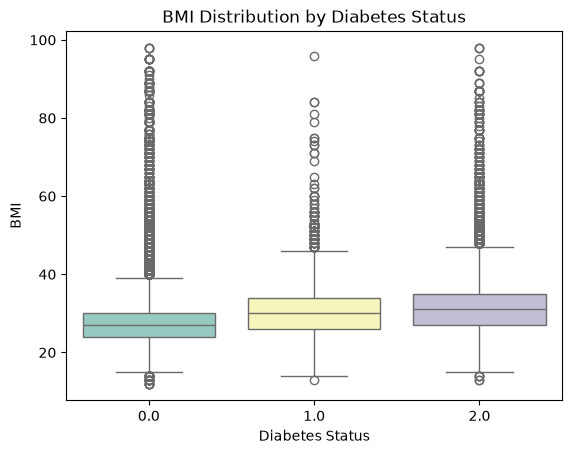

In [32]:
sns.boxplot(
    data=df,
    x="Diabetes_012",
    y="BMI",
    hue="Diabetes_012",
    palette="Set3",
    legend=False
)
plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("BMI")
plt.show()